In [17]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)

library loaded successfully
****************************************************************************************************


In [18]:
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)

In [24]:
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

W0000 00:00:1786086780.246358    5717 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1786086780.248922    5717 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9
I0000 00:00:1786086787.682680    5717 cuda_dnn.cc:461] Loaded cuDNN version 92101


Saved: ./feature_activation_signal.png


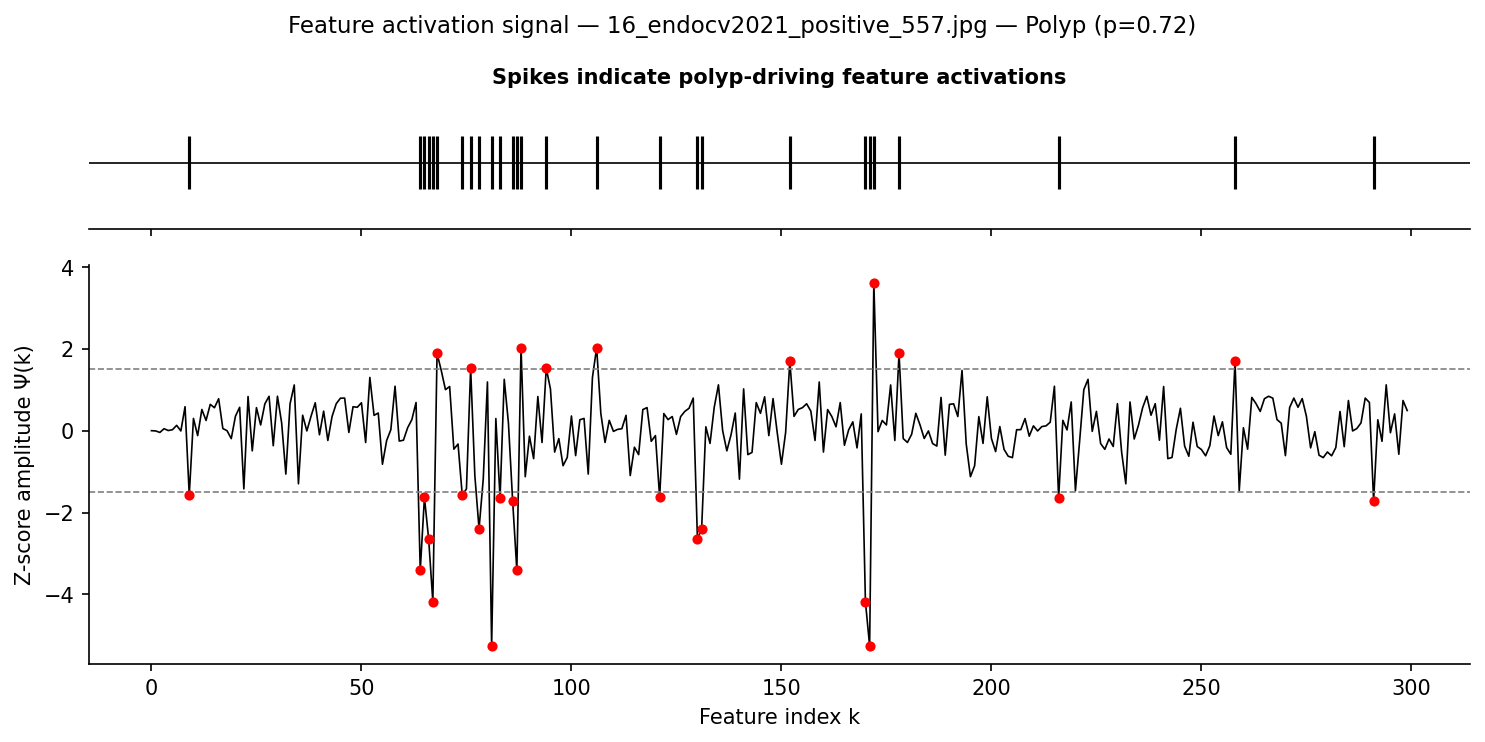

In [25]:
"""
Feature Activation Spike Diagram Generator (PCC-EELM Classification Branch)

Given a colonoscopy image path, a frozen TR-SE-NET model (.keras), and a saved
ELM ensemble weight bundle (.pkl), this script reproduces a matched-filter-style
spike visualization: a top "event" track that fires only where the model's
Z-scored feature trace exceeds a spike threshold, and a bottom raw signal trace.
If the model predicts non-polyp, no spikes are drawn on the top track.

Requires: your KerasPCCLayer / dice_coef / iou_metric / bce_dice_loss /
focal_tversky_loss definitions to be importable (same as your training script).
"""

import os
import pickle
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = 256
SPIKE_THRESHOLD = 1.5  # z-score threshold, tau_spike (Psi(k) magnitude)

# ─────────────────────────────────────────────────────────────────────────
# Your elm_artifacts.npz does NOT contain score_min / score_max / tau_star
# (these are training-set-wide statistics, not derivable from one image).
# Fill these in from your training run's printed output (evaluate_logistic_
# ensemble already prints "Optimal Threshold" for tau_star; add one line to
# print np.min(final_scores)/np.max(final_scores) in that function to get
# SCORE_MIN/SCORE_MAX, then hardcode them here once).
# ─────────────────────────────────────────────────────────────────────────
SCORE_MIN = None    # e.g. -3.42  <- fill in from your training log
SCORE_MAX = None    # e.g.  3.87  <- fill in from your training log
TAU_STAR = 0.51      # from your earlier training-set optimal threshold


# ─────────────────────────────────────────────────────────────────────────
# STAGE 1: Preprocess image exactly as in training (CLAHE + unsharp mask)
# ─────────────────────────────────────────────────────────────────────────
def preprocess_image(image_path):
    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    cl = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    enhanced = cv2.cvtColor(cv2.merge((cl, a, b)), cv2.COLOR_LAB2RGB)
    blur = cv2.medianBlur(enhanced, 3)
    sharp = cv2.addWeighted(enhanced, 1.5, blur, -0.5, 0)
    return np.expand_dims(sharp / 255.0, axis=0).astype(np.float32)


# ─────────────────────────────────────────────────────────────────────────
# STAGE 2: Load frozen model, slice up to clf_pcc_layer (fallback: clf_gap)
# ─────────────────────────────────────────────────────────────────────────
def load_feature_extractor(model_path):
    model = tf.keras.models.load_model(model_path, custom_objects={
        'KerasPCCLayer': KerasPCCLayer, 'dice_coef': dice_coef,
        'iou_metric': iou_metric, 'bce_dice_loss': bce_dice_loss,
        'focal_tversky_loss': focal_tversky_loss
    }, compile=False)
    try:
        layer_name = 'clf_pcc_layer'
        _ = model.get_layer(layer_name)
    except Exception:
        layer_name = 'clf_gap'
    return tf.keras.Model(inputs=model.input, outputs=model.get_layer(layer_name).output)


# ─────────────────────────────────────────────────────────────────────────
# STAGE 3: Run the full PCC-EELM pipeline (Eq. 26-31) on one image
# ─────────────────────────────────────────────────────────────────────────
def load_bundle(elm_weights_path):
    """Loads the ELM artifact bundle from either .npz (np.savez) or .pkl (pickle)."""
    ext = os.path.splitext(elm_weights_path)[1].lower()
    if ext == '.npz':
        raw = np.load(elm_weights_path, allow_pickle=True)
        # np.savez stores everything as 0-d object arrays or plain arrays;
        # .item() unwraps 0-d object arrays (sklearn objects, python lists/floats).
        def unwrap(key):
            val = raw[key]
            return val.item() if val.shape == () else val
        return {k: unwrap(k) for k in raw.files}
    elif ext in ('.pkl', '.pickle'):
        with open(elm_weights_path, 'rb') as f:
            return pickle.load(f)
    else:
        raise ValueError(f"Unsupported ELM weights file type: {ext} (expected .npz or .pkl)")


def classify_and_extract(image_path, model_path, elm_weights_path):
    bundle = load_bundle(elm_weights_path)

    W_in, b_in = bundle['W_input'], bundle['b_input']
    ensemble_weights = bundle['ensemble_weights']       # list of W_out^(lambda)
    selector_support = bundle['selector_support']       # boolean mask from SelectKBest
    scaler_center = bundle['scaler_center_']             # RobustScaler median
    scaler_scale = bundle['scaler_scale_']                # RobustScaler IQR

    # Prefer calibration stats saved in the .npz; fall back to hardcoded constants.
    score_min = bundle.get('score_min', SCORE_MIN)
    score_max = bundle.get('score_max', SCORE_MAX)
    tau_star = bundle.get('tau_star', TAU_STAR)
    if score_min is None or score_max is None:
        raise ValueError(
            "score_min / score_max not found in the .npz and SCORE_MIN / SCORE_MAX "
            "are not set. Run recompute_calibration_stats.py first, or fill in the "
            "SCORE_MIN / SCORE_MAX constants at the top of this file."
        )

    extractor = load_feature_extractor(model_path)
    inp = preprocess_image(image_path)
    feats = extractor(inp, training=False)
    feats_flat = tf.reshape(feats, [1, -1]).numpy().astype(np.float32)

    X_selected = feats_flat[:, selector_support]                          # Eq. (26)
    X_scaled = ((X_selected - scaler_center) / scaler_scale).astype(np.float32)  # Eq. (27)

    H = np.tanh(X_scaled @ W_in + b_in)                   # Eq. (28)
    raw_scores = [H @ w for w in ensemble_weights]
    score = np.mean(raw_scores, axis=0).item()             # Eq. (30) -- .item() unwraps the (1,) array to a scalar
    prob = float(np.clip((score - score_min) / (score_max - score_min + 1e-7), 0.0, 1.0))  # Eq. (31)
    is_polyp = prob > tau_star                             # Eq. (33)

    z_signal = X_scaled.flatten()
    z_signal = (z_signal - np.mean(z_signal)) / (np.std(z_signal) + 1e-7)  # Psi(k)
    return z_signal, prob, is_polyp, tau_star


# ─────────────────────────────────────────────────────────────────────────
# STAGE 4: Draw the matched-filter-style spike diagram
# ─────────────────────────────────────────────────────────────────────────
def plot_spike_diagram(z_signal, prob, is_polyp, tau_star, image_path, output_path=None):
    n = len(z_signal)
    x = np.arange(n)
    spike_idx = np.where(np.abs(z_signal) > SPIKE_THRESHOLD)[0] if is_polyp else np.array([], dtype=int)

    fig, (ax_top, ax_bottom) = plt.subplots(
        2, 1, figsize=(10, 5), dpi=150, sharex=True,
        gridspec_kw={'height_ratios': [1, 3]}
    )

    # Top panel: event track (only fires if polyp predicted)
    ax_top.axhline(0, color='black', linewidth=0.8)
    if len(spike_idx) > 0:
        ax_top.eventplot(spike_idx, lineoffsets=0, linelengths=0.8, colors='black')
    ax_top.set_ylim(-1, 1)
    ax_top.set_yticks([])
    ax_top.set_title(
        "Spikes indicate polyp-driving feature activations" if is_polyp
        else "No spikes detected \u2014 no polyp-driving activation found",
        fontsize=10, fontweight='bold'
    )
    for spine in ('top', 'right', 'left'):
        ax_top.spines[spine].set_visible(False)

    # Bottom panel: raw Z-scored feature trace
    ax_bottom.plot(x, z_signal, color='black', linewidth=0.8)
    ax_bottom.axhline(SPIKE_THRESHOLD, linestyle='--', color='gray', linewidth=0.8)
    ax_bottom.axhline(-SPIKE_THRESHOLD, linestyle='--', color='gray', linewidth=0.8)
    if len(spike_idx) > 0:
        ax_bottom.scatter(spike_idx, z_signal[spike_idx], color='red', s=15, zorder=5)
    ax_bottom.set_xlabel("Feature index k")
    ax_bottom.set_ylabel("Z-score amplitude \u03a8(k)")
    for spine in ('top', 'right'):
        ax_bottom.spines[spine].set_visible(False)

    label = f"Polyp (p={prob:.2f})" if is_polyp else f"Normal (p={prob:.2f})"
    fig.suptitle(f"Feature activation signal \u2014 {os.path.basename(image_path)} \u2014 {label}", fontsize=11)
    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {output_path}")
    plt.show()


# ─────────────────────────────────────────────────────────────────────────
# ENTRY POINT
# ─────────────────────────────────────────────────────────────────────────
def generate_spike_diagram(image_path, model_path, elm_weights_path, output_path=None):
    z_signal, prob, is_polyp, tau_star = classify_and_extract(image_path, model_path, elm_weights_path)
    plot_spike_diagram(z_signal, prob, is_polyp, tau_star, image_path, output_path)
    return prob, is_polyp




if __name__ == "__main__":
    IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/16_endocv2021_positive_557.jpg"
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    ELM_WEIGHTS_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
    OUTPUT_PATH = "./feature_activation_signal.png"

    generate_spike_diagram(IMAGE_PATH, MODEL_PATH, ELM_WEIGHTS_PATH, OUTPUT_PATH)